In [2]:
# Mount Google Drive so we can access Dataset V1
from google.colab import drive

drive.mount('/content/drive')

# Import Path for handling dataset folders and files
from pathlib import Path

# Set the main Dataset V1 location
DATASET_PATH = Path("/content/drive/MyDrive/material_version")
V1_PATH = DATASET_PATH / "dataset_v1"

# Define the train, validation and test image folders
TRAIN_DIR = V1_PATH / "train"
VAL_DIR = V1_PATH / "val"
TEST_DIR = V1_PATH / "test"

# Define the COCO annotation folder
ANNOTATION_DIR = V1_PATH / "annotations"

# Define the annotation JSON files
TRAIN_JSON = ANNOTATION_DIR / "instances_train.json"
VAL_JSON = ANNOTATION_DIR / "instances_val.json"
TEST_JSON = ANNOTATION_DIR / "instances_test.json"

# Check that the important folders and files exist
print("Dataset V1:", V1_PATH.exists())
print("Train folder:", TRAIN_DIR.exists())
print("Validation folder:", VAL_DIR.exists())
print("Test folder:", TEST_DIR.exists())
print("Annotation folder:", ANNOTATION_DIR.exists())
print("Train JSON:", TRAIN_JSON.exists())
print("Validation JSON:", VAL_JSON.exists())
print("Test JSON:", TEST_JSON.exists())

Mounted at /content/drive
Dataset V1: True
Train folder: True
Validation folder: True
Test folder: True
Annotation folder: True
Train JSON: True
Validation JSON: True
Test JSON: True


In [3]:
# Mount Google Drive so we can access Dataset V1
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
V1_PATH = Path("/content/drive/MyDrive/material_version/dataset_v1")

TRAIN_DIR = V1_PATH / "train"
VAL_DIR = V1_PATH / "val"
TEST_DIR = V1_PATH / "test"
ANNOTATION_DIR = V1_PATH / "annotations"

In [5]:
# Check Dataset V1 contents

print("Dataset V1:", V1_PATH)

print("\nTrain images:", len(list(TRAIN_DIR.glob("*.jpg"))))
print("Validation images:", len(list(VAL_DIR.glob("*.jpg"))))
print("Test images:", len(list(TEST_DIR.glob("*.jpg"))))

print("\nAnnotation files:", len(list(ANNOTATION_DIR.glob("*.json"))))

Dataset V1: /content/drive/MyDrive/material_version/dataset_v1

Train images: 5177
Validation images: 943
Test images: 1092

Annotation files: 3


In [6]:
import json

# Load the three COCO annotation files
with open(TRAIN_JSON, "r") as f:
    train_data = json.load(f)

with open(VAL_JSON, "r") as f:
    val_data = json.load(f)

with open(TEST_JSON, "r") as f:
    test_data = json.load(f)

# Check image and annotation counts
print("TRAIN")
print("Images:", len(train_data["images"]))
print("Annotations:", len(train_data["annotations"]))

print("\nVALIDATION")
print("Images:", len(val_data["images"]))
print("Annotations:", len(val_data["annotations"]))

print("\nTEST")
print("Images:", len(test_data["images"]))
print("Annotations:", len(test_data["annotations"]))

# Print class names
print("\nClasses:")
for category in train_data["categories"]:
    print(category["id"], "->", category["name"])

TRAIN
Images: 5177
Annotations: 9118

VALIDATION
Images: 943
Annotations: 1390

TEST
Images: 1092
Annotations: 1828

Classes:
1 -> rov
2 -> plant
3 -> animal_fish
4 -> animal_starfish
5 -> animal_shells
6 -> animal_crab
7 -> animal_eel
8 -> animal_etc
9 -> trash_etc
10 -> trash_fabric
11 -> trash_fishing_gear
12 -> trash_metal
13 -> trash_paper
14 -> trash_plastic
15 -> trash_rubber
16 -> trash_wood


In [7]:
# Create YOLO dataset structure inside Dataset V1

YOLO_PATH = V1_PATH / "yolo_dataset"

for split in ["train", "val", "test"]:
    (YOLO_PATH / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_PATH / "labels" / split).mkdir(parents=True, exist_ok=True)

print("YOLO dataset path:", YOLO_PATH)
print("Structure created successfully.")

YOLO dataset path: /content/drive/MyDrive/material_version/dataset_v1/yolo_dataset
Structure created successfully.


In [8]:
# Use the existing YOLO dataset

YOLO_PATH = V1_PATH / "yolo_dataset"

YOLO_TRAIN_IMAGES = YOLO_PATH / "images" / "train"
YOLO_VAL_IMAGES = YOLO_PATH / "images" / "val"
YOLO_TEST_IMAGES = YOLO_PATH / "images" / "test"

YOLO_TRAIN_LABELS = YOLO_PATH / "labels" / "train"
YOLO_VAL_LABELS = YOLO_PATH / "labels" / "val"
YOLO_TEST_LABELS = YOLO_PATH / "labels" / "test"

print("YOLO dataset:", YOLO_PATH.exists())
print("Train images:", YOLO_TRAIN_IMAGES.exists())
print("Train labels:", YOLO_TRAIN_LABELS.exists())
print("Val images:", YOLO_VAL_IMAGES.exists())
print("Val labels:", YOLO_VAL_LABELS.exists())
print("Test images:", YOLO_TEST_IMAGES.exists())
print("Test labels:", YOLO_TEST_LABELS.exists())

YOLO dataset: True
Train images: True
Train labels: True
Val images: True
Val labels: True
Test images: True
Test labels: True


In [9]:
# Check the existing YOLO data.yaml

YAML_PATH = YOLO_PATH / "data.yaml"

print("data.yaml exists:", YAML_PATH.exists())

if YAML_PATH.exists():
    print("\n--- data.yaml ---")
    print(YAML_PATH.read_text())

data.yaml exists: True

--- data.yaml ---
path: /content/drive/MyDrive/material_version/dataset_v1/yolo_dataset
train: images/train
val: images/val
test: images/test
nc: 16
names:
- rov
- plant
- animal_fish
- animal_starfish
- animal_shells
- animal_crab
- animal_eel
- animal_etc
- trash_etc
- trash_fabric
- trash_fishing_gear
- trash_metal
- trash_paper
- trash_plastic
- trash_rubber
- trash_wood



In [10]:
!pip install -q ultralytics

import ultralytics
import torch

print("Ultralytics version:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 832.0 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.4/75.4 kB 2.3 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics version: 8.4.146
CUDA available: False


In [11]:
from ultralytics import YOLO

# Load pretrained YOLO11n model
model = YOLO("yolo11n.pt")

print("YOLO11n loaded successfully.")

YOLO11n loaded successfully.


In [12]:
# Training configuration

TRAIN_EPOCHS = 100
IMAGE_SIZE = 640
BATCH_SIZE = 16
DEVICE = 0

print("Epochs:", TRAIN_EPOCHS)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Device:", DEVICE)
print("Dataset:", YAML_PATH)

Epochs: 100
Image size: 640
Batch size: 16
Device: 0
Dataset: /content/drive/MyDrive/material_version/dataset_v1/yolo_dataset/data.yaml


In [ ]:
# Train YOLO11n for 100 epochs

results = model.train(
    data=str(YAML_PATH),
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/drive/MyDrive/material_version/yolo_runs",
    name="yolo11n_100_epochs",
    pretrained=True
)

Ultralytics 8.4.145 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/material_version/dataset_v1/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=y

In [13]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/material_version/yolo_runs/yolo11n_100_epochs/weights/last.pt")

results = model.train(resume=True)

Ultralytics 8.4.146 🚀 Python-3.13.15 torch-2.11.0+cpu 


ValueError: Invalid CUDA 'device=0' requested. Use 'device=cpu' or pass valid CUDA device(s) if available, i.e. 'device=0' or 'device=0,1,2,3' for Multi-GPU.

torch.cuda.is_available(): False
torch.cuda.device_count(): 0
os.environ['CUDA_VISIBLE_DEVICES']: None
See https://pytorch.org/get-started/locally/ for up-to-date torch install instructions if no CUDA devices are seen by torch.


In [14]:
from pathlib import Path

LAST_PT = Path(
    "/content/drive/MyDrive/material_version/yolo_runs/yolo11n_100_epochs/weights/last.pt"
)

print("Checkpoint exists:", LAST_PT.exists())
print("Checkpoint:", LAST_PT)

Checkpoint exists: True
Checkpoint: /content/drive/MyDrive/material_version/yolo_runs/yolo11n_100_epochs/weights/last.pt


In [19]:
from pathlib import Path

RUN_PATH = Path("/content/drive/MyDrive/material_version/yolo_runs/yolo11n_100_epochs-2")
BEST_PT = RUN_PATH / "weights" / "best.pt"
LAST_PT = RUN_PATH / "weights" / "last.pt"

print("Best checkpoint:", BEST_PT.exists())
print("Last checkpoint:", LAST_PT.exists())
print("\nRun files:")
for f in RUN_PATH.iterdir():
    print(f.name)

Best checkpoint: True
Last checkpoint: True

Run files:
weights
args.yaml
labels.jpg
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
train_batch29160.jpg
train_batch29161.jpg
train_batch29162.jpg
results.csv


In [20]:
import pandas as pd

RESULTS_CSV = RUN_PATH / "results.csv"

df = pd.read_csv(RESULTS_CSV)
df.columns = df.columns.str.strip()

print("Epochs completed:", len(df))
print("\nLast 5 epochs:")
display(df.tail())

Epochs completed: 91

Last 5 epochs:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
86,87,11179.2,0.71794,0.52484,0.98843,0.36614,0.18195,0.15668,0.10499,1.33791,3.51832,1.51588,0.000074,0.000074,0.000074
87,88,11291.3,0.72445,0.51858,0.99474,0.25808,0.21344,0.15418,0.10146,1.33883,3.52205,1.51377,0.000069,0.000069,0.000069
88,89,11403.8,0.70500,0.51492,0.98338,0.35689,0.18725,0.15338,0.10087,1.35655,3.54945,1.51327,0.000064,0.000064,0.000064
89,90,11514.1,0.71316,0.51415,0.98821,0.27148,0.19388,0.15223,0.09903,1.37120,3.65328,1.53038,0.000059,0.000059,0.000059
90,91,11619.0,0.68913,0.44690,0.96745,0.25464,0.20937,0.14830,0.09658,1.38052,3.58351,1.52952,0.000055,0.000055,0.000055


In [21]:
print("First epoch:", df["epoch"].min())
print("Last epoch:", df["epoch"].max())

# Find the best validation mAP50-95
best_idx = df["metrics/mAP50-95(B)"].idxmax()
best_row = df.loc[best_idx]

print("\nBest epoch:", int(best_row["epoch"]))
print("Precision:", best_row["metrics/precision(B)"])
print("Recall:", best_row["metrics/recall(B)"])
print("mAP50:", best_row["metrics/mAP50(B)"])
print("mAP50-95:", best_row["metrics/mAP50-95(B)"])

First epoch: 1
Last epoch: 91

Best epoch: 79
Precision: 0.1845
Recall: 0.21504
mAP50: 0.15563
mAP50-95: 0.10509


In [23]:
from ultralytics import YOLO

BEST_PT = RUN_PATH / "weights" / "best.pt"

model = YOLO(str(BEST_PT))

val_results = model.val(
    data=str(YAML_PATH),
    split="val",
    imgsz=640,
    batch=16,
    device="cpu"
)

Ultralytics 8.4.146 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,585,272 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 1.2±0.4 ms, read: 0.2±0.1 MB/s, size: 57.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/material_version/dataset_v1/yolo_dataset/labels/val.cache... 943 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 943/943 172.0Mit/s 0.0s
val: /content/drive/MyDrive/material_version/dataset_v1/yolo_dataset/images/val/vid_000532_frame0000001.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 59/59 6.5s/it 6:24
                   all        943       1389      0.184      0.215      0.156      0.105
                   rov        239        274      0.383      0.668  

In [25]:
val_results = model.val(
    data=str(YAML_PATH),
    split="val",
    imgsz=640,
    batch=16,
    device="cpu"
)

Ultralytics 8.4.146 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,585,272 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.8±0.1 ms, read: 28.7±11.4 MB/s, size: 61.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/material_version/dataset_v1/yolo_dataset/labels/val.cache... 943 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 943/943 47.1Mit/s 0.0s
val: /content/drive/MyDrive/material_version/dataset_v1/yolo_dataset/images/val/vid_000532_frame0000001.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 59/59 6.2s/it 6:03
                   all        943       1389      0.184      0.215      0.156      0.105
                   rov        239        274      0.383      0.668 

In [26]:
print("Precision:", val_results.box.mp)
print("Recall:", val_results.box.mr)
print("mAP50:", val_results.box.map50)
print("mAP50-95:", val_results.box.map)

Precision: 0.18413171283887497
Recall: 0.21520658054515832
mAP50: 0.15581784655244216
mAP50-95: 0.10516060781050997


In [28]:
test_results = model.val(
    data=str(YAML_PATH),
    split="test",
    imgsz=640,
    batch=16,
    device="cpu"
)

Ultralytics 8.4.146 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,585,272 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 1.2±0.2 ms, read: 0.2±0.0 MB/s, size: 48.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/material_version/dataset_v1/yolo_dataset/labels/test.cache... 1092 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1092/1092 86.4Mit/s 0.0s
val: /content/drive/MyDrive/material_version/dataset_v1/yolo_dataset/images/test/vid_000143_frame0000013.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 69/69 5.2s/it 5:56
                   all       1092       1827      0.321      0.199      0.185      0.112
                   rov        335        477      0.548      0.5

In [29]:
print("TEST RESULTS")
print("Precision:", test_results.box.mp)
print("Recall:", test_results.box.mr)
print("mAP50:", test_results.box.map50)
print("mAP50-95:", test_results.box.map)

TEST RESULTS
Precision: 0.3208882674415581
Recall: 0.19936648838848875
mAP50: 0.18476899306368366
mAP50-95: 0.11174816586916606


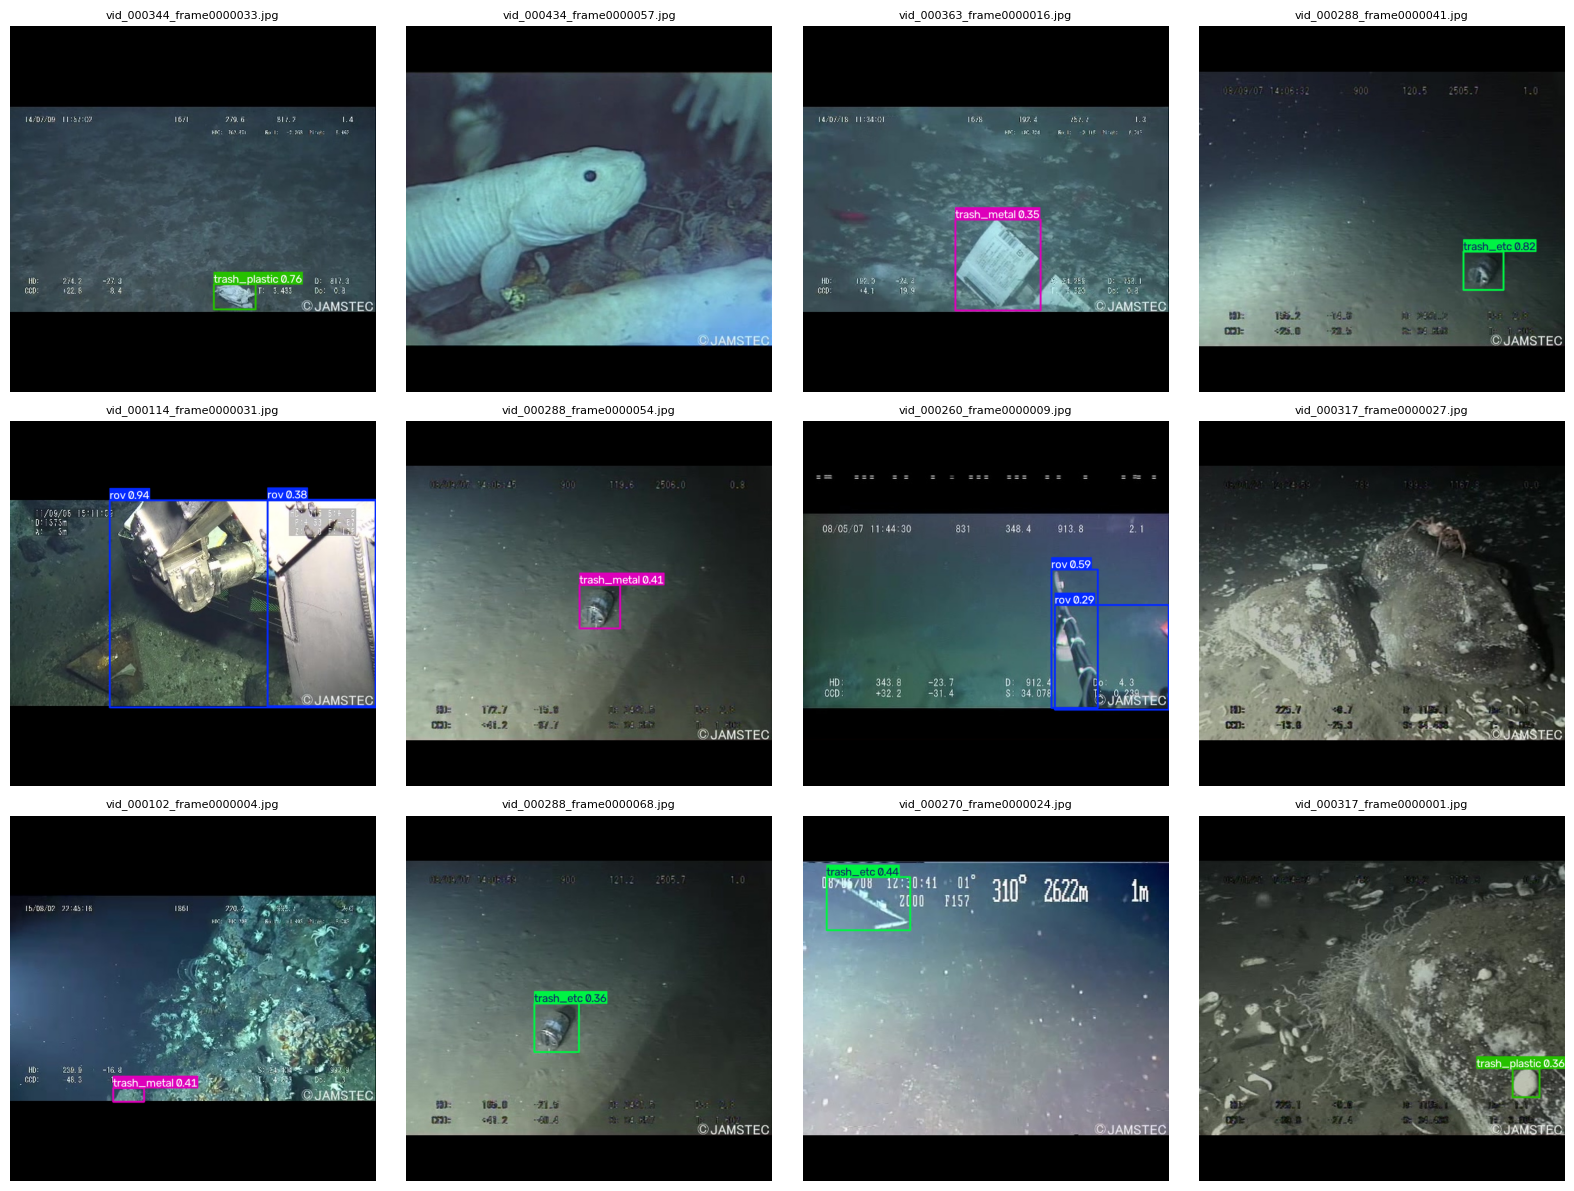

In [31]:
# Random qualitative analysis on 12 test images

import random
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Get all test images
test_images=list(TEST_DIR.glob("*.jpg"))

# Select 12 random test images
random.seed(42)
sample_images=random.sample(test_images,12)

# Run predictions
prediction_results=model.predict(
    source=[str(img) for img in sample_images],
    imgsz=640,
    conf=0.25,
    device="cpu",
    verbose=False
)

# Display results in a 3x4 grid
fig,axes=plt.subplots(3,4,figsize=(16,12))

for ax,result,img_path in zip(axes.ravel(),prediction_results,sample_images):
    plotted=result.plot()
    plotted=plotted[:,:,::-1]

    ax.imshow(plotted)
    ax.set_title(Path(img_path).name,fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

Metric	50 epochs	Current (~92 epochs)	Change
Precision	~0.249–0.252	0.3209	↑
Recall	~0.188	0.1994	↑
mAP@50	0.186	0.1848	≈ same
mAP@50–95	0.119	0.1117	↓

In [32]:
# Run the trained model on the test set and save predictions

prediction_results=model.predict(
    source=str(TEST_DIR),
    imgsz=640,
    conf=0.25,
    device="cpu",
    save=True,
    project="/content/drive/MyDrive/material_version/yolo_runs",
    name="yolo11n_92epoch_test_predictions",
    max_det=50
)

# Print where the prediction images were saved
print("Prediction results saved to:")
print("/content/drive/MyDrive/material_version/yolo_runs/yolo11n_92epoch_test_predictions")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/1092 /content/drive/MyDrive/material_version/dataset_v1/test/vid_000020_frame0000002.jpg: 640x640 1 trash_etc, 403.6ms
image 2/1092 /content/drive/MyDrive/material_version/dataset_v1/test/vid_000020_frame0000003.jpg: 640x640 1 animal_fish, 1 animal_etc, 300.7ms
image 3/1092 /content/drive/MyDrive/material_version/dataset_v1/test/vid_000020_frame0000004.jpg: 640x640 (no detections), 340.9ms
image 4/1092 /content/drive/MyDrive/material_version/datas